In [2]:

import icepyx as ipx
import numpy as np
import xarray as xr
import pandas as pd
import h5py
import os, json
from pprint import pprint
import dask.dataframe as dd
import rioxarray as rxr
import rasterio
import rasterio
from pyproj import Transformer
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam, read_hdf5_atl03_coordinate

In [3]:
import glob
import re
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator


from readers.add_atl08_info import add_atl08_classed_flag
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam_h5py

def read_hdf5_atl03_beam_h5py(filename, beam, verbose=False):
    """
    ATL03 原始数据读取
    Args:
        filename (str): h5文件路径
        beam (str): 光束
        verbose (bool): 输出HDF5信息

    Returns:
        返回ATL03光子数据的heights和geolocation信息
    """

    # 打开HDF5文件进行读取
    file_id = h5py.File(os.path.expanduser(filename), 'r')

    # 输出HDF5文件信息
    if verbose:
        print(file_id.filename)
        print(list(file_id.keys()))
        print(list(file_id['METADATA'].keys()))

    # 为ICESat-2 ATL03变量和属性分配python字典
    atl03_mds = {}

    # 读取文件中每个输入光束
    beams = [k for k in file_id.keys() if bool(re.match('gt\\d[lr]', k))]
    if beam not in beams:
        print('请填入正确的光束代码')
        return

    atl03_mds['heights'] = {}
    atl03_mds['geolocation'] = {}
    atl03_mds['bckgrd_atlas'] = {}

    # -- 获取每个HDF5变量
    # -- ICESat-2 Measurement Group
    for key, val in file_id[beam]['heights'].items():
        atl03_mds['heights'][key] = val[:]

    # -- ICESat-2 Geolocation Group
    for key, val in file_id[beam]['geolocation'].items():
        atl03_mds['geolocation'][key] = val[:]

    for key, val in file_id[beam]['bckgrd_atlas'].items():
        atl03_mds['bckgrd_atlas'][key] = val[:]

    return atl03_mds

def get_atl03_x_atc(atl03_mds):
    val = atl03_mds

    # 初始化
    val['heights']['x_atc'] = np.zeros_like(val['heights']['h_ph']) + np.nan
    val['heights']['y_atc'] = np.zeros_like(val['heights']['h_ph']) + np.nan
    val['geolocation']['ref_elev_all'] = np.zeros_like(val['heights']['h_ph'])

    # -- ATL03 Segment ID
    segment_id = val['geolocation']['segment_id']
    # -- 分段中的第一个光子（转换为基于0的索引）
    segment_index_begin = val['geolocation']['ph_index_beg'] - 1
    # -- 分段中的光子事件数
    segment_pe_count = val['geolocation']['segment_ph_cnt']
    # -- 每个ATL03段的沿轨道距离
    segment_distance = val['geolocation']['segment_dist_x']
    # -- 每个ATL03段的轨道长度
    segment_length = val['geolocation']['segment_length']

    # -- 对ATL03段进行迭代，以计算40m的平均值
    # -- 在ATL03中基于1的索引：无效==0
    # -- 此处为基于0的索引：无效==-1
    segment_indices, = np.nonzero((segment_index_begin[:-1] >= 0) &
                                  (segment_index_begin[1:] >= 0))
    for j in segment_indices:
        # -- j 段索引
        idx = segment_index_begin[j]
        # -- 分段中的光子数（使用2个ATL03分段）
        c1 = np.copy(segment_pe_count[j])
        c2 = np.copy(segment_pe_count[j + 1])
        cnt = c1 + c2

        # -- 沿轨道和跨轨道距离
        # -- 获取当前段光子列表，idx当前段(j)第一个光子数量，c1当前段光子数量，idx+c1当前段长度
        distance_along_x = np.copy(val['heights']['dist_ph_along'][idx: idx + cnt])
        ref_elev = np.copy(val['geolocation']['ref_elev'][j])
        # -- 给当前段的光子加上当前段沿轨道距离
        distance_along_x[:c1] += segment_distance[j]
        distance_along_x[c1:] += segment_distance[j + 1]
        distance_along_y = np.copy(val['heights']['dist_ph_across'][idx: idx + cnt])

        val['heights']['x_atc'][idx: idx + cnt] = distance_along_x
        val['heights']['y_atc'][idx: idx + cnt] = distance_along_y
        val['geolocation']['ref_elev_all'][idx: idx + c1] += ref_elev

def read_data(filepath, beam, mask_lat, mask_lon):
    """
    读取数据，返回沿轨道距离和高程距离
    :param filepath: h5文件路径
    :param beam: 轨道光束
    :param mask_lat: 维度范围
    :param mask_lon: 经度范围
    :return:
    """
    atl03_file = glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_beam(atl03_file[0], beam=beam, verbose=False)
    # 添加沿轨道距离到数据中
    get_atl03_x_atc(is2_atl03_mds)
    # 选择范围
    d3 = is2_atl03_mds
    subset1 = (d3['heights']['lat_ph'] >= min(mask_lat)) & (d3['heights']['lat_ph'] <= max(mask_lat))
    print(subset1.shape, 'sss')
    zz = d3['heights']['h_ph']
    print(zz.shape, 'zz')
    if mask_lon is not None:
        if mask_lon[0] is not None and mask_lon[1] is None:
            subset1 = subset1 & (d3['heights']['x_atc'] >= mask_lon[0])
        elif mask_lon[0] is None and mask_lon[1] is not None:
            subset1 = subset1 & (d3['heights']['x_atc'] <= mask_lon[1])
        else:
            subset1 = subset1 & (d3['heights']['x_atc'] >= min(mask_lon)) & (d3['heights']['x_atc'] <= max(mask_lon))
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    ref_elev = d3['geolocation']['ref_elev_all'][subset1]
    print(d3['heights'])
    print(d3.keys())
    print(d3['heights'].keys(), 'height')
    print(d3['geolocation'].keys(), 'location key')
    print(d3['bckgrd_atlas'].keys(), 'bckgrd_atlas')
    print(d3['heights']['quality_ph'], 'quality_ph')
    del d3, subset1
    return x_act, h, signal_conf_ph, lat, lon, ref_elev

def read_all_beam_coordinate(filepath, mask_lat, mask_lon):
    """
    读取所有波束的数据
    :param filepath:
    :param mask_lat:
    :param mask_lon:
    :return:
    """
    atl03_file = glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_coordinate(atl03_file[0])

    # 禁止加载全部数据
    # if mask_lat is None or len(mask_lat) == 0 or mask_lon is None or len(mask_lon) == 0:
    #     return False

    d3 = is2_atl03_mds
    if mask_lon is None and mask_lat is None:
        # 加载全部数据
        return d3
    for beam in is2_atl03_mds.keys():
        subset1 = (d3[beam]['lat'] >= min(mask_lat)) & (d3[beam]['lat'] <= max(mask_lat))
        subset1 = subset1 & (d3[beam]['lon'] >= min(mask_lon)) & (d3[beam]['lon'] <= max(mask_lon))
        d3[beam]['lat'] = d3[beam]['lat'][subset1]
        d3[beam]['lon'] = d3[beam]['lon'][subset1]
    return d3

def read_hdf5_atl08(filename, beam, verbose=False):
    file_id = h5py.File(os.path.expanduser(filename), 'r')

    # 输出HDF5文件信息
    if verbose:
        print(file_id.filename)
        print(list(file_id.keys()))
        print(list(file_id['METADATA'].keys()))
    # 为ICESat-2 ATL08变量和属性分配python字典
    atl08_mds = {}

    # 读取文件中每个输入光束
    beams = [k for k in file_id.keys() if bool(re.match('gt\\d[lr]', k))]
    if beam not in beams:
        print('请填入正确的光束代码')
        return
    # atl08_land_segement = {}
    # for key, val in file_id[beam]['land_segments'].items():
    #     atl08_land_segement['land_segments'][key] = val[:]
    atl08_mds['land_segments'] = {}
    atl08_mds['signal_photons'] = {}
    print(atl08_mds)
    # -- ICESat-2 Geolocation Group
    for key, val in file_id[beam]['signal_photons'].items():
        print(val)
        atl08_mds['signal_photons'][key] = val[:]

    return atl08_mds

def select_atl03_data(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def select_atl03_data2(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def select_atl03_data3(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) #& (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def get_atl03_data(filepath, beam):
    """
    读取ATL03数据，根据维度截取数据
    Args:
        filepath (str): h5文件路径
        beam (str): 光束
    Returns:
        返回沿轨道距离，高程距离，光子置信度
    """
    atl03_file = glob.glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_beam_h5py(atl03_file[0], beam=beam, verbose=False)
    # 添加沿轨道距离到数据中
    get_atl03_x_atc(is2_atl03_mds)
    return is2_atl03_mds
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam, read_hdf5_atl03_coordinate

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re

def get_atl_group(folder_path_03, folder_path_08):

    alt03_file_list = glob.glob(os.path.join(folder_path_03, '*ATL03*.h5'))
    n = len(alt03_file_list)

    ATL_name_group = []
    for i in range(n):
        
        # find keyword (date and orbit number)
        file_path = alt03_file_list[i]
        time_match = re.search(r'ATL03_(\d{14})_', file_path)
        orbit_match = re.search(r'ATL03_\d{14}_(\d{8})_', file_path)
        Imaging_date = time_match.group(1)[:8]
        orbit_num = orbit_match.group(1)

        # search target ATL03/08 file with the same keyword (data)
        alt03_file_list_ = glob.glob(os.path.join(folder_path_03, f'*ATL03*{Imaging_date}*{orbit_num}*.h5'))
        alt08_file_list = glob.glob(os.path.join(folder_path_08, f'*ATL08*{Imaging_date}*{orbit_num}*.h5'))
        
        # Construct ATL_pair and storage in ATL_name_group( 2-D List)
        if (len(alt08_file_list) == 1) & (len(alt08_file_list) == 1):
            ATL_pair = [alt03_file_list_[0], alt08_file_list[0]]
            ATL_name_group.append(ATL_pair)

    return ATL_name_group

def find_anomaly(indices_list):
    b = []
    if len(indices_list) <= 5:
        value = 100
    else:
        for i in range(1,len(indices_list)):
            b.append(indices_list[i] - indices_list[i-1])
            
        if max(b) > 5:
            index_max = [index for index, value in enumerate(b) if value == max(b)]
            value = indices_list[index_max[0]+1]
        else:
            value = indices_list[0]
        
    return value

def sea_height_cal(input, height_name, derivative_thred):
    
    if  isinstance(input, str):
        data = pd.read_csv(input)
        df = pd.DataFrame(data)
    else:
        df = input
    
    percentile, derivative, derivative_2th = [], [0], [0]
    height_TS = pd.DataFrame()
    
    if len(df) < 100:
        return 0, height_TS
    else:
        
        for i in range(0, 101):
            p = np.percentile(df[height_name], i)
            percentile.append(p)

        height_TS['percentile'] = percentile
        
        height_TS['percentile'][:5] = height_TS['percentile'][5]
        
        short_window, long_window = 5, 10
        height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']

        indices = [index for index, value in enumerate(height_TS['MACD']) if value > derivative_thred]
        target_index = find_anomaly(indices)
        # if indices == []:
        #     indices = [100]

        print(indices[:10], 'indices')
        print(target_index, 'target_index')
        # sea_height = percentile[target_index]
        sea_height = percentile[target_index]
        
        return  sea_height, df, height_TS, target_index
    
def sea_height_cal_for_view(input, height_name, derivative_thred):
    
    if  isinstance(input, str):
        data = pd.read_csv(input)
        df = pd.DataFrame(data)
    else:
        df = input
    
    percentile, derivative, derivative_2th = [], [0], [0]
    height_TS = pd.DataFrame()
    
    if len(df) < 100:
        return 0, height_TS
    else:
        
        for i in range(0, 101):
            p = np.percentile(df[height_name], i)
            percentile.append(p)

        height_TS['percentile'] = percentile
        short_window, long_window = 5, 10
        # height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        # height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        # height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']
        
        height_TS['percentile'][:5] = height_TS['percentile'][5]

    #----------------------------------------------------------------
        height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']
        # height_TS['MACD'] = height_TS['Z'].ewm(span=5, adjust=False).mean()
        # height_TS['DEA'] =  height_TS['DIF'].ewm(span=25, adjust=False).mean()
        # height_TS['MACD'] = height_TS['DIF'] - height_TS['DEA']
    
    #----------------------------------------------------------------
    
        indices = [index for index, value in enumerate(height_TS['MACD']) if value > derivative_thred]
        target_index = find_anomaly(indices)
        # if indices == []:
        #     indices = [100]

        print(indices[:10], 'indices')
        print(target_index, 'target_index')
        #sea_height = percentile[target_index]
        sea_height = percentile[target_index]
        return  sea_height, df , height_TS, target_index
    
def icesat_gt_processing(alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = True):
    
    sea_height_list = []
    df_list = []
    df_sea_point_remove_list = []
    
    # calculate each beams
    for i in range(len(beam)):
    
        atl03_data = get_atl03_data(alt03_path, beam[i])
        add_atl08_classed_flag(alt08_path, beam[i], atl03_data)
        x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
        z = pd.DataFrame()
        z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
        z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
        re_accumulate =  z.groupby('distance').agg(
            
            mean_height = ('height', 'mean'),
            mean_lon = ('longtitude', 'mean'),
            mean_lat = ('latitude', 'mean')
        ).reset_index()

        if re_accumulate.empty | len(re_accumulate) < 200:
            continue

        sea_height, df, height_TS, target_index = sea_height_cal_for_view(re_accumulate, 'mean_height', sea_thred)  
        if sea_height > 0:
            sea_height_list.append(sea_height)
            df_list.append(df)    
    
    if sea_height_list == []:
        empty = pd.DataFrame()
        return empty, [], [], []

#--------------------------------------------------------------------------------------------------------------  
    log = []
    log.append('sea height list:' + str(sea_height_list) + ' --- ')

    # calculate Final_sea_height
    
    print(sea_height_list, 'sea_height_list')
    if np.max(sea_height_list) - np.min(sea_height_list) > 1:
        sort_ = np.sort(sea_height_list)
        print('sorted', sort_, type(sort_))
        _ = []
        for i in range(len(sea_height_list)-1):
            _.append(sort_[i+1] - sort_[i])

        index_max = [index for index, value in enumerate(_ ) if value == max(_)]

        if (index_max[0]+1) <= len(sort_)/2:
            index_max = len(sort_)-1
        
        Final_sea_height = sort_[index_max].item()
    else:
        Final_sea_height = np.max(sea_height_list)

    print(Final_sea_height,'Final_sea_height', type(Final_sea_height))
    log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
    
#---------------------------------------------------------------------------------------------------------------
    
    # Apply Final_sea_height for all beams
    for j in range(len(df_list)):
        mask = df_list[j]['mean_height'] > Final_sea_height
        print(type(mask), 'type mask', len(mask), 'mask len')
        
        df_sea_point_remove = df_list[j][mask]
        
        if df_sea_point_remove.empty:
            print(filepath_03 + '_' + beam[j] + ' is empty')
        
        df_sea_point_remove_list.append(df_sea_point_remove)
        
        df_list[j]['sea_height'] = Final_sea_height
        df_list[j]['sea_point'] =  df_list[j]['mean_height'] <= Final_sea_height
        
        if is_display:
           
            plt.figure(figsize=(10, 3))
            plt.plot(df_list[j]['mean_height'], color ='gray',label = 'height')
            plt.plot(df_list[j]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
            plt.scatter(df_list[j].index[df_list[j]['sea_point']], df_list[j]['mean_height'][df_list[j]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
            plt.legend()
            plt.ylabel('height')
            plt.xlabel('photons')
            plt.show()
            
            fig, ax1 = plt.subplots(figsize=(10,3))
            _ = np.arange(0, 101)
            ax1.plot(_, height_TS['percentile'], label = 'percentile', color = 'black')
            ax1.set_xlabel('X-axis')
            ax1.set_ylabel('Height(m)', color = 'black')
            ax1.tick_params(axis='y', labelcolor='black')
           # ax1.axhline(df_list[j]['sea_height'][0], color = 'red', linestyle = '--')
            ax1.legend()
            
            ax2 = ax1.twinx()
            ax2.plot(_, height_TS['MACD'], 'r--', label = 'MACD', color = 'blue')
           # ax2.plot(_, height_TS['Signal'], 'r--', label = 'Signal', color = 'green')
            ax2.set_ylabel('MACD', color = 'blue')

            ax2.tick_params(axis = 'y', labelcolor = 'blue')
            ax2.axhline(0, color = 'gray', linestyle = '--')
            ax2.axvline(target_index, color = 'red', linestyle = '--', label = 'Threshold')
            ax2.legend()
            
            plt.show()

            #-------------------------------------
    
    merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
    
    return merged_df, sea_height_list, Final_sea_height, log

In [4]:
def icesat_gt_processing3_new_for_raw(No ,alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance):
    
    
    osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
    df_sea_point_remove_list = []
    local_strip_height_list = []
    ICESat_2_point_list = []
    log = []
    
    for i in range(len(beam)):
        
        df_list = []
        sea_height_list = []
        
        for j in range(len(beam[i])):
            
            atl03_data = get_atl03_data(alt03_path, beam[i][j])
            add_atl08_classed_flag(alt08_path, beam[i][j], atl03_data)
            x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data3(atl03_data, region_mask, TF_height_range)
            x_origin1, y_origin1, _, lat1, _, _ = select_atl03_data2(atl03_data, region_mask, TF_height_range)
            z = pd.DataFrame()
            z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
            z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
            re_accumulate =  z.groupby('distance').agg(
                
                mean_height = ('height', 'mean'),
                mean_lon = ('longtitude', 'mean'),
                mean_lat = ('latitude', 'mean')
            ).reset_index()
            re_accumulate['Strip_No'] =  str(i) + '_' + beam[i][j]
            if re_accumulate.empty | len(re_accumulate) < 10:
                print('photon less than 200!')
                continue
        
            ICESat_2_point_list.append(re_accumulate)
    
    if ICESat_2_point_list == []:
        merged_df = pd.DataFrame()
        return merged_df
        
    merged_df = pd.concat(ICESat_2_point_list, ignore_index=True)
    return merged_df
    

In [9]:
if __name__ == '__main__':
    
    REGION = 'Region2'
    #----------------------------------------------------------------------------------------
    #--------------------------------------Region 2 -----------------------------------------
    year_list = [2019, 2020, 2021, 2022, 2023]
    year_list = [2022]
    Region_info = {
            'region1': {'name':'wash_bay', 'mask':[[0.041, 0.807], [52.756, 53.163]]},
            'region2': {'name':'Henber'  , 'mask':[[-0.839, 0.382], [53.164, 53.852]]},
            'region3': {'name':'Region2a', 'mask':[[-0.906, -0.060], [53.852, 54.443]]}
        } 
    # Region_info = {

    #         'region1': {'name':'Thames', 'mask':[[-11.3587,2.5279], [49.7857, 59.6268]]},
    #     } 

    detect_region = 'region1'

    print('region:' ,Region_info[detect_region]['name'])
    print('region_mask:', Region_info[detect_region]['mask'])

    region_name = Region_info[detect_region]['name']
    mask = Region_info[detect_region]['mask']
    TF_height_range = [30, 70]
    #----------------------------------------------------------------------------------------
    for j in range(len(year_list)):

        year = year_list[j]

        output_root_path = f'G:\ICESat-2\{REGION}\{REGION}_{region_name}'
        if not os.path.exists(output_root_path):
            os.makedirs(output_root_path)
            output_path = f'G:\ICESat-2\{REGION}\{REGION}_{region_name}\A_{region_name}_30m_{year}_new10_for_all_raw_No7.csv'
        else:
            output_path = f'G:\ICESat-2\{REGION}\{REGION}_{region_name}\A_{region_name}_30m_{year}_new10_for_all_raw_No7.csv'

        log_path =  f'G:\ICESat-2\{REGION}\{REGION}_{region_name}\A_log_{region_name}_{year}_new10_No7.txt'
        

        folder_path_03  = f'G:\ICESat-2\{REGION}\{REGION}_{year}\ATL03_{REGION}_{year}'
        folder_path_08 =  f'G:\ICESat-2\{REGION}\{REGION}_{year}\ATL08_{REGION}_{year}' 
        #beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
        beam = [['gt1l', 'gt1r'], ['gt2l', 'gt2r'] ,['gt3l', 'gt3r']]
        beam = [['gt1l', 'gt1r']]
        ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
        
        output = []
        log_list = []
        
        # for i in range(len(ATL_name_group)):
        for i in range(7,8):
        # for i in range(20, 21):
            
            filepath_03 = ATL_name_group[i][0]
            filepath_08 = ATL_name_group[i][1]
            
            #merged_df = icesat_gt_processing3_new_for_raw(i, filepath_03, filepath_08, beam, mask, TF_height_range,  3000)
            merged_df = icesat_gt_processing3_new_for_raw(i, filepath_03, filepath_08, beam, mask, TF_height_range,  30)
            if merged_df.empty:
                continue
            
            print('------------------------------------')
            output.append(merged_df)
            print('No_'+str(i) + '_' + str(filepath_03) + ' is done')
            print(str(round(i*100/len(ATL_name_group), 2))+ '%' + ' is done')
            # log.append('No_'+str(i) + ': ' + str(filepath_03) + '\n')
            # log_list.append(log)
         #-----------------------------output log info-------------------------------------- 
        
        # with open(log_path, "w") as file:
        #     for logs in log_list:
        #         for log in logs:
        #             file.write(log)
        #-------------------------- output result-------------------------------------------
              
        output = pd.concat(output, ignore_index=True) 
        print('output_len: ',len(output))
        print(output[:10])
        # output.to_csv(output_path)

region: wash_bay
region_mask: [[0.041, 0.807], [52.756, 53.163]]
------------------------------------
No_7_G:\ICESat-2\Region2\Region2_2022\ATL03_Region2_2022\ATL03_20220320032723_13421402_006_01.h5 is done
21.21% is done
output_len:  3030
    distance  mean_height  mean_lon   mean_lat Strip_No
0  5875860.0    49.321136  0.239847  52.756085   0_gt1l
1  5875890.0    49.498226  0.239816  52.756282   0_gt1l
2  5875920.0    49.433273  0.239771  52.756577   0_gt1l
3  5875950.0    49.734882  0.239731  52.756832   0_gt1l
4  5875980.0    49.668850  0.239689  52.757101   0_gt1l
5  5876010.0    49.313152  0.239645  52.757365   0_gt1l
6  5876040.0    49.406296  0.239599  52.757638   0_gt1l
7  5876070.0    49.541531  0.239554  52.757903   0_gt1l
8  5876100.0    49.139427  0.239503  52.758205   0_gt1l
9  5876130.0    49.028904  0.239465  52.758429   0_gt1l


In [ ]:
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd
output.to_csv(output_path)
output_path = f'G:\ICESat-2\ICESAT_2022_raw/A_{REGION}_30m_{year}_new10_for_all_raw_No7.shp'

geometry = [Point(xy) for xy in zip(output['mean_lon'], output['mean_lat'])]
gdf = gpd.GeoDataFrame(output, geometry=geometry, crs='EPSG:4326')

gdf.to_file(output_path)

In [ ]:
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd
output_path = f'G:\ICESat-2\Region2_map\wash_bay_map\A2022/A_{region_name}_30m_{year}_new10_for_all_raw.shp'

geometry = [Point(xy) for xy in zip(output['mean_lon'], output['mean_lat'])]
gdf = gpd.GeoDataFrame(output, geometry=geometry, crs='EPSG:4326')

gdf.to_file(output_path)

In [324]:
gdf.shape

(22117, 5)

In [5]:
import rasterio
def icesat_gt_processing3_new_(No ,alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = True):
    
    
    osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
    df_sea_point_remove_list = []
    local_strip_height_list = []
    log = []
    
    for i in range(len(beam)):
        
        df_list = []
        sea_height_list = []
        
        for j in range(len(beam[i])):
            
            atl03_data = get_atl03_data(alt03_path, beam[i][j])
            add_atl08_classed_flag(alt08_path, beam[i][j], atl03_data)
            x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
            x_origin1, y_origin1, conf, lat1, lon1, classed_pc_flag = select_atl03_data2(atl03_data, region_mask, TF_height_range)
            
            z = pd.DataFrame()
            z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
            z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
            re_accumulate =  z.groupby('distance').agg(
                
                mean_height = ('height', 'mean'),
                mean_lon = ('longtitude', 'mean'),
                mean_lat = ('latitude', 'mean')
            ).reset_index()


            if osgm_path is not None and not re_accumulate.empty:
                
                
                raster = rasterio.open(osgm_path)
                transformer = Transformer.from_crs(4326, raster.crs, always_xy=True)
                xs, ys = transformer.transform(re_accumulate['mean_lon'].values, re_accumulate['mean_lat'].values)
                coords = list(zip(xs, ys))
                re_accumulate['OSGM'] = [val[0] if val is not None else None for val in raster.sample(coords)]
                
                re_accumulate['OH'] = re_accumulate['mean_height'] - re_accumulate['OSGM']
                
                # remove land 
                mask = (re_accumulate['OH'] < 10) & (re_accumulate['OH'] > -10) 
                re_accumulate = re_accumulate[mask]
    

            if re_accumulate.empty | len(re_accumulate) < 200:
                print('photon less than 200!')
                continue

            sea_height, df, height_TS, _index = sea_height_cal(re_accumulate, 'OH', sea_thred)  
            df['Strip_No'] =  str(No) + '_' + beam[i][j]
            print('sea_height',sea_height)
            
            #if sea_height > 0:
            if sea_height > -5:   
                sea_height_list.append(sea_height)
                df_list.append(df)  
             
        if sea_height_list == []:
            # empty = pd.DataFrame()
            # return empty, [], [], []
            continue
        
        
        #--------------------------------------------------------------------------------------------------------------  
        
        log.append('sea height list:' + str(sea_height_list) + ' --- ')

        # calculate Final_sea_height
        
        Final_sea_height = np.max(sea_height_list)
        local_strip_height_list.append(Final_sea_height)
        print('Final_sea_height', Final_sea_height)
        log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
        
        
        #---------------------------------------------------------------------------------------------------------------
    
        # Apply Final_sea_height for all beams
        for k in range(len(df_list)):
            mask = df_list[k]['OH'] > Final_sea_height
            print(type(mask), 'type mask', len(mask), 'mask len')
            
            df_sea_point_remove = df_list[k][mask]
            
            if df_sea_point_remove.empty:
                print(filepath_03 + '_' + beam[i][0] + beam[i][1] + ' is empty')
            
            df_sea_point_remove_list.append(df_sea_point_remove)
            
            df_list[k]['sea_height'] = Final_sea_height
            df_list[k]['sea_point'] =  df_list[k]['OH'] <= Final_sea_height
            
            if is_display:
            
                plt.figure(figsize=(10, 3))
                plt.plot(df_list[k]['OH'], color ='gray',label = 'height')
                plt.plot(df_list[k]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
                plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['OH'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
                plt.legend()
                plt.ylabel('height')
                plt.xlabel('photons')
                plt.show()
                #############
        
        merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
        
    if len(local_strip_height_list) == 0:
        empty = pd.DataFrame()
        return empty, [], [], []
        
    # else:
    #     if np.max(local_strip_height_list) - np.min(local_strip_height_list) > 0.5:
        
    #         mask = merged_df['mean_height'] > np.max(local_strip_height_list)
    #         merged_df = merged_df[mask]
        
    return merged_df, sea_height_list, Final_sea_height, log, df_list, df, x_origin, y_origin, x_origin1, y_origin1, lat, lat1, height_TS, _index

In [6]:
# folder_path_03  = 'G:\ICESat-2\Region4\Region4_2019\ATL03_Region4_2019'
# folder_path_08 = 'G:\ICESat-2\Region4\Region4_2019\ATL08_Region4_2019' 

folder_path_03  = 'G:\ICESat-2\Region2\Region2_2022\ATL03_Region2_2022'
folder_path_08 = 'G:\ICESat-2\Region2\Region2_2022\ATL08_Region2_2022' 

# mask = [[0.273, 1.475], [51.262, 51.863]]
# mask = [[-0.839, 0.382], [53.164, 53.852]]
#mask = [[-2.494, -1.366], [55.380, 56.062]] # Holy_island
#mask = [[0.273, 1.475], [51.262, 51.863]] # Thames 
#mask = [[-4.233, -2.594], [53.171, 53.909]] # Ribble
mask = [[0.041, 0.807], [52.756, 53.163]] # Wash

# mask = Region_info[detect_region]['mask']

# folder_path_03  = f'H:\Region4\Region4_{year}\ATL03_Region4_{year}'
# folder_path_08 =  f'H:\Region4\Region4_{year}\ATL08_Region4_{year}' 
beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
beam3 = [['gt1l', 'gt1r'],['gt2l', 'gt2r'],['gt3l', 'gt3r']]
beam3 = [['gt1l', 'gt1r']]
# beam = ['gt3r']
TF_height_range = [30, 70]

No = 7
ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
filepath_03 = ATL_name_group[No][0]
filepath_08 = ATL_name_group[No][1]
print(filepath_08)

#merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask, TF_height_range, 30, sea_thred = 0.05, is_display = True)

merged_df3, _, _, log, df_list, re_accumulate, x_origin, y_origin, x_origin1, y_origin1, lat, lat1, height_TS, _index = icesat_gt_processing3_new_(No, filepath_03, filepath_08, beam3, mask, TF_height_range, 30, sea_thred = 0.03, is_display = False)
#merged_df3, _, _, log, df_list, re_accumulate, x_origin, y_origin, x_origin1, y_origin1, lat, lat1 = icesat_gt_processing3_new_(No, filepath_03, filepath_08, beam3, mask, TF_height_range, 30, sea_thred = 0.03, is_display = True)

# import geopandas as gpd
# from shapely.geometry import Point
# import pandas as pd
# output_path = f'G:\ICESat-2\Region2_map\wash_bay_map\A2022/z{No}_{beam[0]}_new.shp'
# geometry = [Point(xy) for xy in zip(merged_df3['mean_lon'], merged_df3['mean_lat'])]
# gdf = gpd.GeoDataFrame(merged_df3, geometry=geometry, crs='EPSG:4326')

# gdf.to_file(output_path)

G:\ICESat-2\Region2\Region2_2022\ATL08_Region2_2022\ATL08_20220320032723_13421402_006_01.h5
[26, 27, 28, 29, 30, 31, 32, 33, 34, 35] indices
26 target_index
sea_height -2.619817199707031
[28, 29, 30, 31, 32, 33, 34, 35, 36, 37] indices
28 target_index
sea_height -2.5965760803222655
Final_sea_height -2.5965760803222655
<class 'pandas.core.series.Series'> type mask 1517 mask len
<class 'pandas.core.series.Series'> type mask 1512 mask len


In [13]:
re_accumulate.columns
shp_path = 'G:\ICESat-2\ICESAT_2022_raw\A_Region2_30m_2022_new10_for_all_raw_No7.shp'
k = gpd.read_file(shp_path)
k

,distance,mean_heigh,mean_lon,mean_lat,Strip_No,class,Great_Brit,OH,geometry
0,5875860.0,49.321136,0.239847,52.756085,0_gt1l,3,45.701,3.62014,POINT (0.23985 52.75609)
1,5875890.0,49.498226,0.239816,52.756282,0_gt1l,3,45.701,3.79723,POINT (0.23982 52.75628)
2,5875920.0,49.433273,0.239771,52.756577,0_gt1l,3,45.701,3.73227,POINT (0.23977 52.75658)
3,5875950.0,49.734882,0.239731,52.756832,0_gt1l,3,45.701,4.03388,POINT (0.23973 52.75683)
4,5875980.0,49.668850,0.239689,52.757101,0_gt1l,3,45.701,3.96785,POINT (0.23969 52.7571)
...,...,...,...,...,...,...,...,...,...
3025,5921250.0,55.120007,0.174923,53.162061,0_gt1r,3,45.582,9.53801,POINT (0.17492 53.16206)
3026,5921280.0,55.205254,0.174882,53.162316,0_gt1r,3,45.582,9.62325,POINT (0.17488 53.16232)
3027,5921310.0,55.204956,0.174845,53.162551,0_gt1r,3,45.582,9.62296,POINT (0.17484 53.16255)
3028,5921340.0,55.293045,0.174798,53.162838,0_gt1r,3,45.582,9.71104,POINT (0.1748 53.16284)


In [14]:
msk1 = (k['class'] == 3) & (k['Strip_No'] == '0_gt1l')
msk2 = (k['class'] == 2) & (k['Strip_No'] == '0_gt1l')
msk3 = (k['class'] == 0) & (k['Strip_No'] == '0_gt1l')
# k[msk].shape

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, figsize=(10, 6), gridspec_kw={'height_ratios': [1, 1, 1]})

_ = np.arange(0, 101)

# 第一幅图：折线图（时间序列）
ax1.hist(k[msk2]['OH'].dropna(), bins=100, color='black', edgecolor='gray', alpha=0.5)
#ax1.plot(k[msk2]['OH'], color ='gray',label = 'height')
ax1.set_xlabel('Height (m)')
ax1.set_ylabel('Frequency')
ax1.set_title('Distribution of Height Percentile')

# 第二幅图：直方图（分布）
ax2.hist(k[msk1]['OH'].dropna(), bins=100, color='black', edgecolor='gray', alpha=0.5)
ax2.set_xlabel('Height (m)')
ax2.set_ylabel('Frequency')
ax2.set_title('Distribution of Height Percentile')

# 第二幅图：直方图（分布）
ax3.hist(k[msk3]['OH'].dropna(), bins=100, color='black', edgecolor='gray', alpha=0.5)
ax3.set_xlabel('Height (m)')
ax3.set_ylabel('Frequency')
ax3.set_title('Distribution of Height Percentile')

plt.tight_layout()
plt.show()

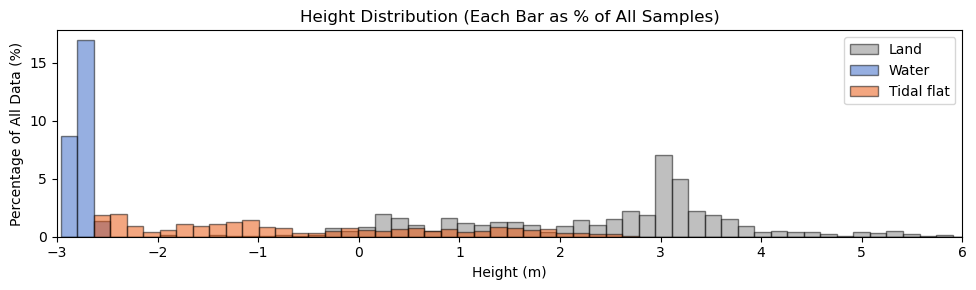

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# 提取数据
data1 = k[msk1]['OH'].dropna()
data2 = k[msk2]['OH'].dropna()
data3 = k[msk3]['OH'].dropna()

# 所有数据拼接，统一 bin
all_data = np.concatenate([data1, data2, data3])
bins = np.linspace(all_data.min(), all_data.max(), 80)

# 计算总数用于归一化
total_count = len(all_data)

# 绘图
fig, ax = plt.subplots(figsize=(10, 3))

# 定义画图函数：每组在所有样本中的百分比
def plot_relative_hist(data, bins, color, label):
    counts, bin_edges = np.histogram(data, bins=bins)
    percent = counts / total_count * 100  # 注意分母是所有数据的数量
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.bar(bin_centers, percent, width=np.diff(bins), align='center',
           alpha=0.5, edgecolor='black', color=color, label=label)

# 绘制三组共享百分比的直方图
plot_relative_hist(data1, bins, color="gray", label='Land')
plot_relative_hist(data2, bins, color="#2F61C4FF", label='Water')
plot_relative_hist(data3, bins, color="#E84F03FF", label='Tidal flat')

# 设置标签
ax.set_xlabel('Height (m)')
ax.set_xlim(-3, 6)
ax.set_ylabel('Percentage of All Data (%)')
ax.set_title('Height Distribution (Each Bar as % of All Samples)')
ax.legend()

plt.tight_layout()
plt.show()


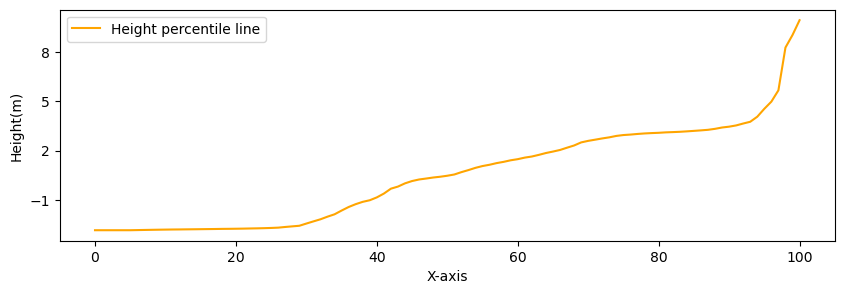

In [16]:
fig, ax1 = plt.subplots(figsize=(10, 3))
_ = np.arange(0, 101)

# 折线图：左侧 Y 轴
ax1.set_yticks(np.arange(-4, 13, 3))
ax1.plot(_, height_TS['percentile'], label='Height percentile line', color='orange', zorder=3)
ax1.set_xlabel('X-axis')
ax1.set_ylabel('Height(m)', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.legend(loc='upper left')

# # 柱状图：右侧 Y 轴
# ax2 = ax1.twinx()
# ax2.bar(_, re_accumulate['OH'], width=1.0, color='gray', alpha=0.3, label='MACD Bar', zorder=1)
# ax2.set_ylabel('MACD', color='blue')
# ax2.tick_params(axis='y', labelcolor='blue')
# ax2.legend(loc='upper right')


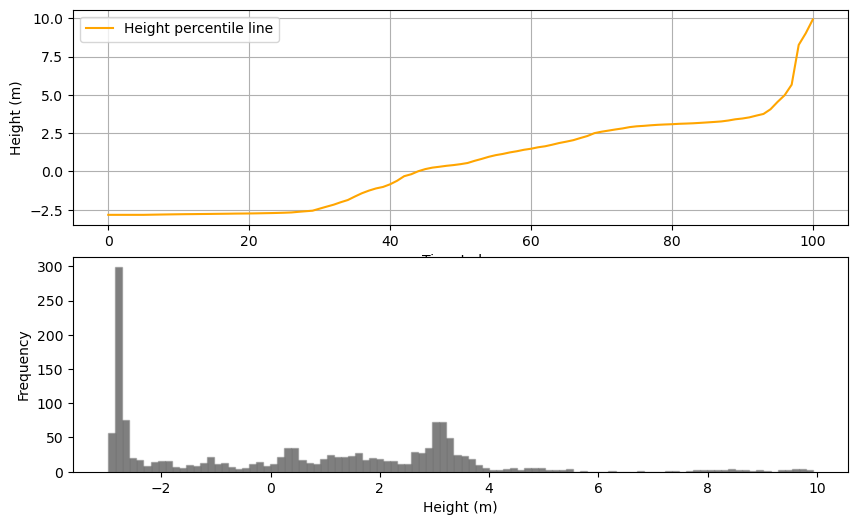

In [281]:
# fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(10, 6), gridspec_kw={'height_ratios': [1, 1]})
fig, (ax1, ax2) = plt.subplots(
    nrows=2,
    figsize=(10, 6),
    gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.15}  # 减小上下图间距
)
_ = np.arange(0, 101)

# 第一幅图：折线图（时间序列）
ax1.plot(_, height_TS['percentile'], label='Height percentile line', color='orange')
#ax1.plot(df_list[0]['OH'], color ='gray',label = 'height')
# ax1.set_ylim(-3, -2)
ax1.set_ylabel('Height (m)')
ax1.set_xlabel('Time Index')
ax1.legend()
ax1.grid(True)

# 第二幅图：直方图（分布）
ax2.hist(re_accumulate['OH'].dropna(), bins=100, color='black', edgecolor='gray', alpha=0.5)
ax2.set_xlabel('Height (m)')
ax2.set_ylabel('Frequency')
# ax2.set_title('Distribution of Height Percentile')

plt.tight_layout()
plt.show()


In [31]:
len(df_list[0]) + len(df_list[1])

3029

In [17]:
msk1 = (k['class'] == 3) & (k['Strip_No'] == '0_gt1l')
msk2 = (k['class'] == 2) & (k['Strip_No'] == '0_gt1l')
msk3 = (k['class'] == 0) & (k['Strip_No'] == '0_gt1l')

In [20]:
df_list_ = k[(k['Strip_No'] == '0_gt1l')]
df_list_
df_list_land = df_list_[df_list_['class'] == 3]
df_list_water = df_list_[df_list_['class'] == 2]
df_list_TF = df_list_[df_list_['class'] == 0]
# print(len(df_list[0]))

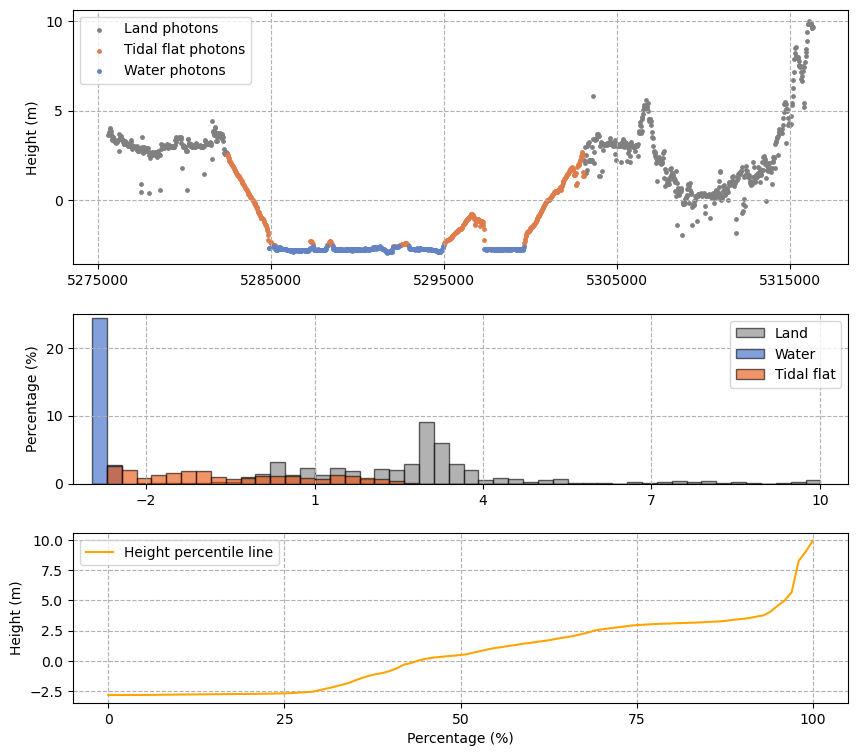

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 示例数据
percentile = height_TS['percentile'].dropna()
x = np.arange(len(percentile))

fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, figsize=(10, 9), gridspec_kw={'height_ratios': [3, 2, 2], 'hspace': 0.25})
ax1.ticklabel_format(style='plain', axis='x')  # 关闭科学计数法

# 上方折线图：高度-时间序列
# ax1.scatter(lat*100000, y_origin,  color ="#144098FF",label = 'Photon filtered by ATL08', s=3)
# ax1.plot(df_list[0]['OH'], color ='gray',label = 'height')
# ax1.scatter(df_list[0]['mean_lat']*100000, df_list[0]['OH'], color ="#144098FF", s=3, label = 'Refined ICESat-2 ATL03 photons after Step1')
ax1.scatter(df_list_land['mean_lat']*100000, df_list_land['OH'], color ='gray', s=6, label = 'Land photons')
ax1.scatter(df_list_TF['mean_lat']*100000, df_list_TF['OH'], color = "#DF7C4BFF", s=6, label = 'Tidal flat photons')
ax1.scatter(df_list_water['mean_lat']*100000, df_list_water['OH'], color = "#6383C2FF", s=6, label = 'Water photons')

ax1.set_yticks(np.arange(-0, 11, 5))
# ax1.set_ylabel('Height (m)', color='black')
ax1.set_xticks(np.arange(5275000, 5320000, 10000))
# ax1.set_yticks(np.arange(0, 100, 20))
# ax1.set_xlabel('Time Index')
ax1.set_ylabel('Height (m)')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True)
ax1.legend(loc='upper left')
ax1.grid(linestyle='--')

# # 下方直方图：高度值的频率分布
# ax2.hist(percentile, bins=100, color='gray', edgecolor='black', alpha=0.5)
# # ax2.set_xlabel('Height (m)')
# ax2.set_ylabel('Frequency')
# # ax2.set_title('Distribution of Height Percentile')
# ax2.grid(True)
# ax2.legend(loc='upper left')
# 提取数据
data1 = k[msk1]['OH'].dropna()
data2 = k[msk2]['OH'].dropna()
data3 = k[msk3]['OH'].dropna()

# 所有数据拼接，统一 bin
all_data = np.concatenate([data1, data2, data3])
bins = np.linspace(all_data.min(), all_data.max(), 50)

# 计算总数用于归一化
total_count = len(all_data)

# 绘图
# fig, ax = plt.subplots(figsize=(10, 3))

# 定义画图函数：每组在所有样本中的百分比
def plot_relative_hist(data, bins, color, label):
    counts, bin_edges = np.histogram(data, bins=bins)
    percent = counts / total_count * 100  # 注意分母是所有数据的数量
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax2.bar(bin_centers, percent, width=np.diff(bins), align='center',
           alpha=0.6, edgecolor='black', color=color, label=label)

# 绘制三组共享百分比的直方图
plot_relative_hist(data1, bins, color="gray", label='Land')
plot_relative_hist(data2, bins, color="#2F61C4FF", label='Water')
plot_relative_hist(data3, bins, color="#E84F03FF", label='Tidal flat')

# 设置标签
# ax2.set_xlabel('Height (m)')
ax2.set_ylim(0, 25)
ax2.set_xlim(-3.3, 10.5)
ax2.set_xticks(np.arange(-2, 11, 3))
ax2.set_yticks(np.arange(0, 26, 10))
ax2.set_ylabel('Percentage (%)')
ax2.grid(True)
ax2.grid(linestyle='--')
# ax2.set_title('Height Distribution (Each Bar as % of All Samples)')
ax2.legend()


ax3.plot(_, height_TS['percentile'], label='Height percentile line', color='orange', zorder=5)
ax3.set_xticks(np.arange(0, 101, 25))
ax3.set_ylabel('Height (m)')
ax3.set_xlabel('Percentage (%)')
ax3.legend(loc='upper left')
ax3.grid(True)
ax3.grid(linestyle='--')

plt.tight_layout()
plt.show()



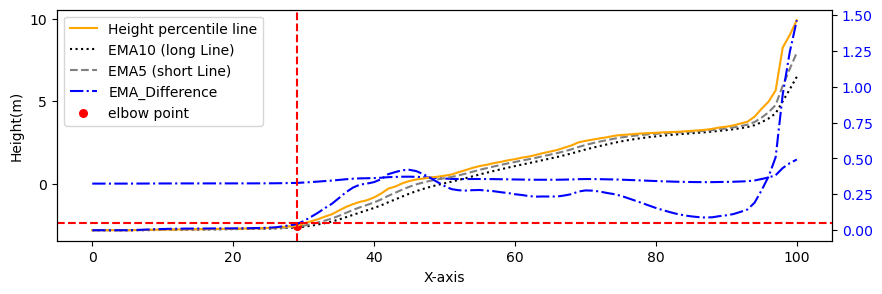

In [313]:
fig, ax1 = plt.subplots(figsize=(10,3))
_ = np.arange(0, 101)
ax1.plot(_, height_TS['percentile'], label = 'Height percentile line', color = 'orange', zorder=5)
ax1.set_yticks(np.arange(-5, 13, 5))
ax1.plot(_,height_TS['EMA10'], label='EMA10 (long Line)', color="black",linestyle = ':', zorder=1) #10A276FF
ax1.plot(_,height_TS['EMA5'], label='EMA5 (short Line)', color="gray",linestyle = '--', zorder=2)#F46906FF
ax1.plot(_, height_TS['MACD'], label='EMA_Difference' ,color='blue',linestyle = '-.', zorder=1)
ax1.tick_params(axis = 'y', labelcolor = 'blue')
ax1.scatter(_index+1, height_TS['percentile'][_index], color='red', s=30, label='elbow point' ,zorder=3)
# ax1.grid(True)
# ax1.grid(linestyle='--')
ax1.set_xlabel('X-axis')
ax1.set_ylabel('Height(m)', color = 'black')
ax1.tick_params(axis='y', labelcolor='black')
                # ax1.axhline(df_list[j]['sea_height'][0], color = 'red', linestyle = '--')


ax1.set_ylabel('Height(m)', color = 'black')
ax1.legend()
ax2 = ax1.twinx()



ax2.plot(_, height_TS['MACD'], label='MACD Bar' ,color='blue',linestyle = '-.', zorder=1)
ax2.tick_params(axis = 'y', labelcolor = 'blue')
# ax2.axhline(0.05, color = 'gray', linestyle = '--', zorder=2)
# ax2.axvline(_index+1, color = 'gray', linestyle = '--', label = 'Threshold', zorder=2)



ax2.axhline(0.05, color = 'red', linestyle = '--', zorder=2)
ax2.axvline(_index+1, color = 'red', linestyle = '--', label = 'Threshold', zorder=2)

# ax2.set_ylabel('MACD', color = 'blue')
# ax2.legend(loc='upper left')
# ax2.legend()
# ax1.legend(loc='lower right', bbox_to_anchor=(1, 1))
# ax2.set_ylabel('MACD', color = 'blue')
# ax2.legend()
                


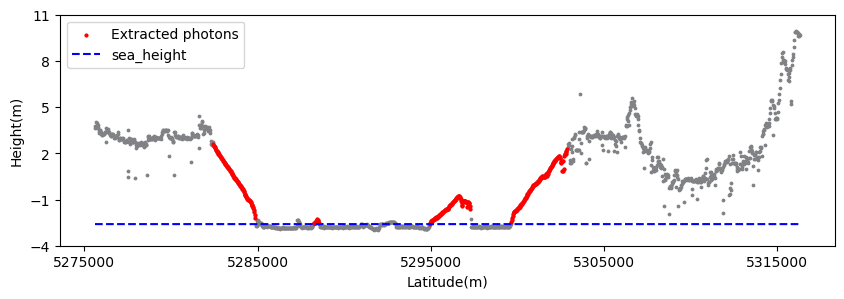

In [ ]:
k = 0    
plt.figure(figsize=(10, 3))


#plt.scatter(df_list[k]['mean_lat']*100000, df_list[k]['OH'], color ="#144098FF",label = 'Photon after Mean_filter', s=3)
plt.scatter(df_list[k]['mean_lat']*100000, df_list[k]['OH'], color ="#818286FF", s=3)
#plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.1)
j = df_list[k]['mean_lat']*100000
z = df_list[k]['OH']
plt.scatter(j[255:346], z[255:346], color='red', label = 'Extracted photons', s=4, zorder=1)
plt.scatter(j[471:483], z[471:483], color='red', s=4, zorder=1)
plt.scatter(j[721:809], z[721:809], color='red', s=4, zorder=1)
plt.scatter(j[896:1017], z[896:1017], color='red', s=4, zorder=1)
#plt.scatter(j[624:647], z[624:647], color='red', s=15, zorder=1)
# plt.axvline(j[255], color = 'orange', linestyle = '-.',  zorder=2)
# plt.axvline(j[357], color = 'orange', linestyle = '-.',  zorder=2)

# plt.axvline(j[471], color = 'orange', linestyle = '-.',  zorder=2)
# plt.axvline(j[483], color = 'orange', linestyle = '-.', zorder=2)

# plt.axvline(j[721], color = 'orange', linestyle = '-.',  zorder=2)
# plt.axvline(j[809], color = 'orange', linestyle = '-.',  zorder=2)

# plt.axvline(j[896], color = 'orange', linestyle = '-.',  zorder=2)
# plt.axvline(j[1017], color = 'orange', linestyle = '-.',  zorder=2)

plt.plot(df_list[k]['mean_lat']*100000,  df_list[k]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
plt.legend()
plt.yticks(np.arange(-4, 12, 3))
# plt.xticks(np.arange(5275000, 5320000, 10000))
plt.ticklabel_format(style='plain', axis='x')
plt.ylabel('Height(m)')
plt.xlabel('Latitude(m)')
plt.show()

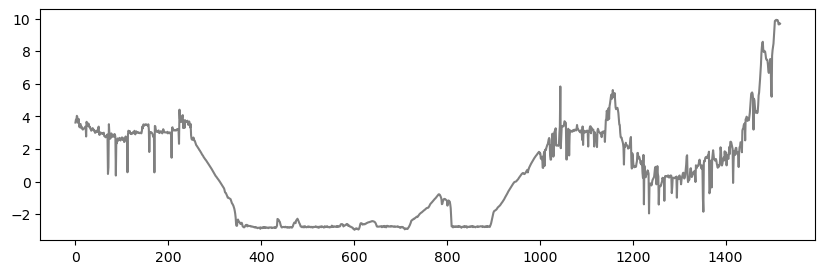

In [212]:
plt.figure(figsize=(10, 3))
plt.plot(df_list[k]['OH'], color ="gray",label = 'Photon after Mean_filter')

In [177]:
df_list[k].columns

Index(['distance', 'mean_height', 'mean_lon', 'mean_lat', 'OSGM', 'OH',
       'Strip_No', 'sea_height', 'sea_point'],
      dtype='object')

(80363,)


Text(0.5, 3.722222222222216, 'Latitude(m)')

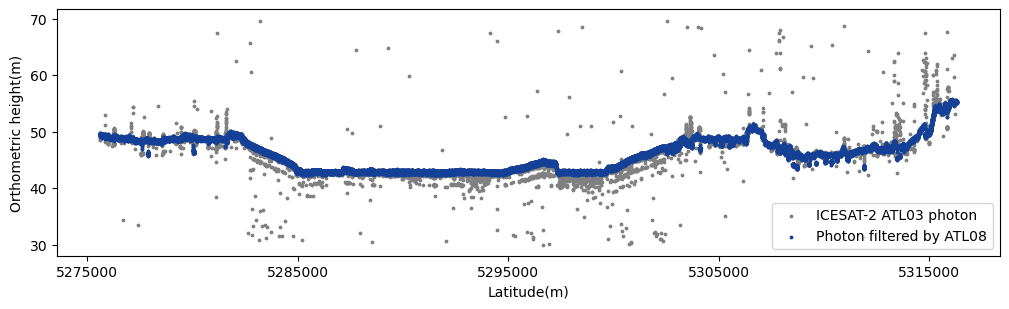

In [22]:
x_origin, y_origin
print(x_origin.shape)
plt.figure(figsize=(10, 3))
x_min, x_max = np.min(x_origin), np.max(x_origin)
plt.xticks(np.arange(5275000, 5320000, 10000))
plt.scatter(lat1*100000, y_origin1,  color ='gray',label = 'ICESAT-2 ATL03 photon', s=3)
plt.scatter(lat*100000, y_origin,  color ="#144098FF",label = 'Photon filtered by ATL08', s=3)
plt.ticklabel_format(style='plain', axis='x')  # 关闭科学计数法
plt.tight_layout()
plt.legend()

plt.ylabel('Orthometric height(m)')
plt.xlabel('Latitude(m)')

# plt.xticks(ticks)
# plt.ticklabel_format(style='plain', axis='x')  # 关闭科学计数法
# plt.tight_layout()
# plt.legend()
# plt.show()

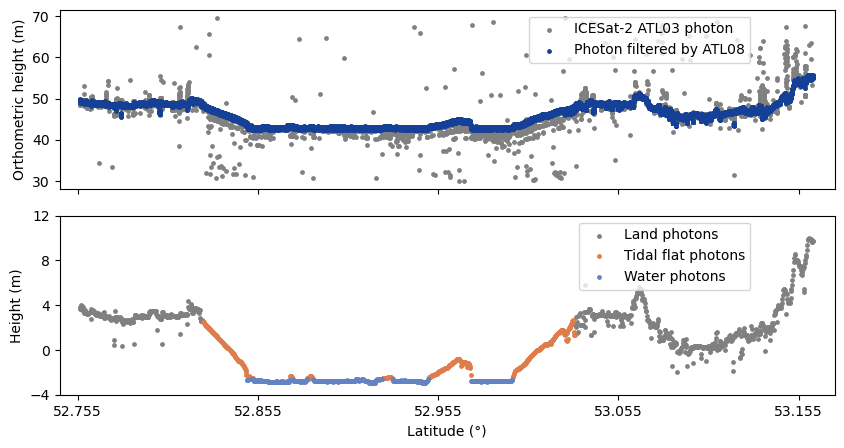

In [45]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={'height_ratios': [2, 2], 'hspace': 0.15})  # 两行一列，x轴共享

# -------- 图1 --------

axes[1].scatter(df_list_land['mean_lat'], df_list_land['OH'], 
                color='gray', s=6, label='Land photons')
axes[1].scatter(df_list_TF['mean_lat'], df_list_TF['OH'], 
                color="#DF7C4BFF", s=6, label='Tidal flat photons')
axes[1].scatter(df_list_water['mean_lat'], df_list_water['OH'], 
                color="#6383C2FF", s=6, label='Water photons')

axes[1].set_yticks(np.arange(-4, 12.1, 4))
axes[1].set_ylabel('Height (m)')
axes[1].ticklabel_format(style='plain', axis='x')
# axes[1].grid(linestyle='--')
# axes[1].grid(False)
axes[1].legend(loc='upper right')
axes[1].legend(
    loc='upper right',
    bbox_to_anchor=(0.90, 1)  # 往左偏移，把 0.95 调小或调大
)
axes[1].set_xlabel('Latitude (°)')

# -------- 图2 --------
axes[0].scatter(lat1, y_origin1, color='gray', label='ICESat-2 ATL03 photon', s=6)
axes[0].scatter(lat, y_origin, color="#144098FF", label='Photon filtered by ATL08', s=6)

axes[0].set_ylabel('Orthometric height (m)')

axes[0].ticklabel_format(style='plain', axis='x')
axes[0].grid(linestyle='--')
axes[0].grid(False)
axes[0].legend(loc='upper right')
axes[0].legend(
    loc='upper right',
    bbox_to_anchor=(0.90, 1)  # 往左偏移，把 0.95 调小或调大
)

# -------- 调整整体布局 --------
num_s, num_e = 5274500, 5317500
plt.xlim(num_s/100000, num_e/100000)
# plt.xticks(np.arange(5275000, 5320000, 10000))  # 设置全局 x 轴刻度
plt.xticks(np.arange(5275500/100000, num_e/100000, 0.1))
plt.tight_layout()
plt.show()


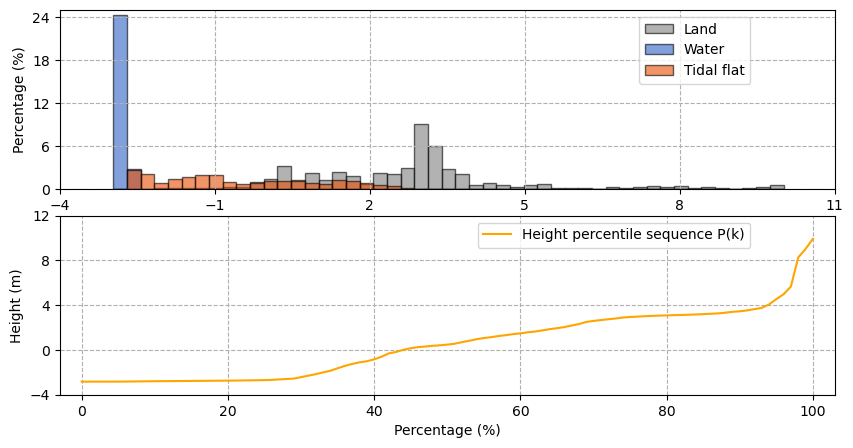

In [ ]:
percentile = height_TS['percentile'].dropna()
x = np.arange(len(percentile))

fig, (ax2, ax3) = plt.subplots(nrows=2, figsize=(10, 5), gridspec_kw={'height_ratios': [2, 2], 'hspace': 0.15})
ax1.ticklabel_format(style='plain', axis='x')  # 关闭科学计数法

# 提取数据
data1 = k[msk1]['OH'].dropna()
data2 = k[msk2]['OH'].dropna()
data3 = k[msk3]['OH'].dropna()

# 所有数据拼接，统一 bin
all_data = np.concatenate([data1, data2, data3])
bins = np.linspace(all_data.min(), all_data.max(), 50)

# 计算总数用于归一化
total_count = len(all_data)

# 定义画图函数：每组在所有样本中的百分比
def plot_relative_hist(data, bins, color, label):
    counts, bin_edges = np.histogram(data, bins=bins)
    percent = counts / total_count * 100  # 注意分母是所有数据的数量
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax2.bar(bin_centers, percent, width=np.diff(bins), align='center',
           alpha=0.6, edgecolor='black', color=color, label=label)

# 绘制三组共享百分比的直方图
plot_relative_hist(data1, bins, color="gray", label='Land')
plot_relative_hist(data2, bins, color="#2F61C4FF", label='Water')
plot_relative_hist(data3, bins, color="#E84F03FF", label='Tidal flat')

# 设置标签
# ax2.set_xlabel('Height (m)')
ax2.set_ylim(0, 25)
ax2.set_xlim(-3.3, 10.5)
ax2.set_xticks(np.arange(-2, 11, 3))
ax2.set_xticks(np.arange(-4, 11.1, 3))
ax2.set_yticks(np.arange(0, 25, 6))
ax2.set_ylabel('Percentage (%)')
ax2.grid(True)
ax2.grid(linestyle='--')
# ax2.set_title('Height Distribution (Each Bar as % of All Samples)')
ax2.legend(
    loc='upper right',
    bbox_to_anchor=(0.90, 1)  # 往左偏移，把 0.95 调小或调大
)



ax3.plot(_, height_TS['percentile'], label=R'Height percentile sequence P(k)', color='orange', zorder=5)
ax3.set_xticks(np.arange(0, 101, 20))
ax3.set_xlim(-3, 103)
ax3.set_yticks(np.arange(-4, 12.1, 4))
ax3.set_ylabel('Height (m)')
ax3.set_xlabel('Percentage (%)')
# ax3.legend(loc='upper right')
ax3.legend(
    loc='upper right',
    bbox_to_anchor=(0.90, 1)  # 往左偏移，把 0.95 调小或调大
)
ax3.grid(linestyle='--')

plt.tight_layout()
plt.show()



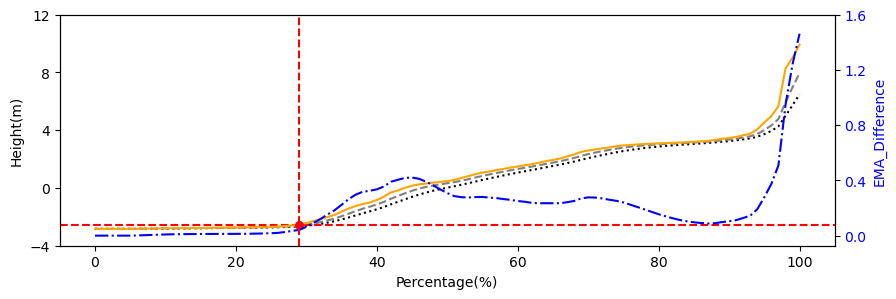

In [47]:
fig, ax1 = plt.subplots(figsize=(10,3))
_ = np.arange(0, 101)
ax1.scatter(_index+1, height_TS['percentile'][_index], color='red', s=30, label='elbow point' ,zorder=6)
ax1.plot(_, height_TS['percentile'], label = 'Height percentile line', color = 'orange', zorder=5)
ax1.set_yticks(np.arange(-5, 13, 5))
ax1.plot(_,height_TS['EMA10'], label='EMA10 (long Line)', color="black",linestyle = ':', zorder=1) #10A276FF
ax1.plot(_,height_TS['EMA5'], label='EMA5 (short Line)', color="gray",linestyle = '--', zorder=2)#F46906FF
# ax1.plot(_, height_TS['MACD'], label='EMA_Difference' ,color='blue',linestyle = '-.', zorder=1)
ax1.tick_params(axis = 'y', labelcolor = 'blue')


# ax1.grid(True)
# ax1.grid(linestyle='--')
ax1.set_xlabel('Percentage(%)')
ax1.set_yticks(np.arange(-4, 12.1, 4))
ax1.set_ylabel('Height(m)', color = 'black')
ax1.tick_params(axis='y', labelcolor='black')
                # ax1.axhline(df_list[j]['sea_height'][0], color = 'red', linestyle = '--')


ax1.set_ylabel('Height(m)', color = 'black')
# ax1.legend(
#     loc='upper right',
#     bbox_to_anchor=(0.90, 1)  # 往左偏移，把 0.95 调小或调大
# )
ax2 = ax1.twinx()



ax2.plot(_, height_TS['MACD'], label='MACD Bar' ,color='blue',linestyle = '-.', zorder=1)
ax2.tick_params(axis = 'y', labelcolor = 'blue')
ax2.set_yticks(np.arange(0, 1.61, 0.4))
# ax2.axhline(0.05, color = 'gray', linestyle = '--', zorder=2)
# ax2.axvline(_index+1, color = 'gray', linestyle = '--', label = 'Threshold', zorder=2)

ax2.set_ylabel(r'EMA_Difference', color='blue')

ax1.axhline(height_TS['percentile'][_index], color = 'red', linestyle = '--', zorder=2)
# ax2.axhline(0.03, color = 'red', linestyle = '--', zorder=2)
ax2.axvline(_index+1, color = 'red', linestyle = '--', label = 'Threshold', zorder=2)



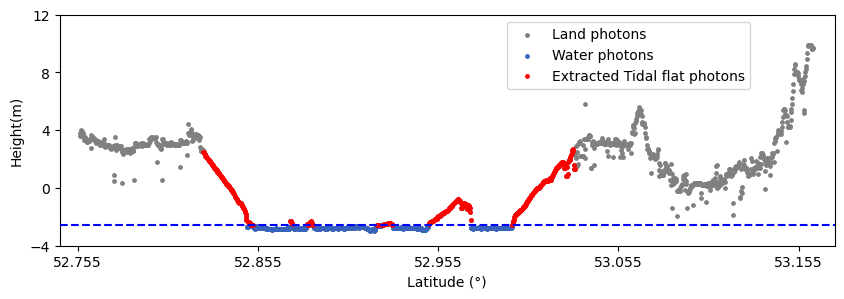

In [74]:
k = 0    
plt.figure(figsize=(10, 3))


# plt.scatter(df_list[k]['mean_lat']*100000, df_list[k]['OH'], color ="#144098FF",label = 'Photon after Mean_filter', s=6)
plt.scatter(df_list[k]['mean_lat'], df_list[k]['OH'], color ="gray",label = 'Land photons', s=6)
plt.scatter(df_list_water['mean_lat'], df_list_water['OH'], 
                color="#3763BBFF", s=6, label='Water photons')
plt.scatter(df_list_TF['mean_lat'], df_list_TF['OH'], color = "red", s=6, label = 'Extracted Tidal flat photons')
# plt.scatter(df_list_water['mean_lat']*100000, df_list_water['OH'], 
#                 color="blue", s=6, label='Water photons')
# plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.1)
plt.legend()
plt.yticks(np.arange(-4, 13, 5))
plt.yticks(np.arange(-4, 12.1, 4))
plt.xticks(np.arange(5275000/100000, 5320000/100000, 10000/100000))
plt.axhline(-2.59, color = 'blue', linestyle = '--', zorder=3)
plt.ticklabel_format(style='plain', axis='x')
plt.ylabel('Height(m)')
plt.xlabel('Latitude (°)')
plt.legend(
    loc='upper right',
    bbox_to_anchor=(0.90, 1)  # 往左偏移，把 0.95 调小或调大
)

num_s, num_e = 5274500/100000, 5317500/100000
plt.xlim(num_s, num_e)
# plt.xticks(np.arange(5275000, 5320000, 10000))  # 设置全局 x 轴刻度
plt.xticks(np.arange(5275500/100000, num_e, 0.1))
plt.show()

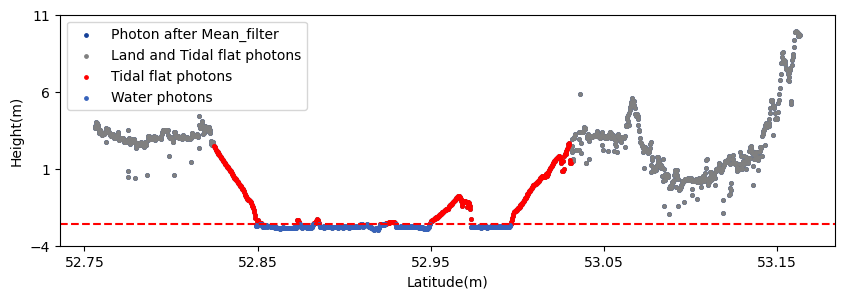

In [57]:
k = 0    
plt.figure(figsize=(10, 3))
plt.scatter(df_list[k]['mean_lat'], df_list[k]['OH'], color ="#144098FF",label = 'Photon after Mean_filter', s=6)
plt.scatter(df_list[k]['mean_lat'], df_list[k]['OH'], color ="gray",label = 'Land and Tidal flat photons', s=6)
plt.scatter(df_list_TF['mean_lat'], df_list_TF['OH'], 
                color="red", s=6, label='Tidal flat photons')
plt.scatter(df_list_water['mean_lat'], df_list_water['OH'], 
                color="#3763BBFF", s=6, label='Water photons')
#plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.1)
plt.legend()
plt.yticks(np.arange(-4, 13, 5))
ax1.set_yticks(np.arange(-5, 13, 5))
plt.xticks(np.arange(5275000/100000, 5320000/100000, 10000/100000))
plt.axhline(-2.59, color = 'red', linestyle = '--', zorder=2)
plt.ticklabel_format(style='plain', axis='x')
plt.ylabel('Height(m)')
plt.xlabel('Latitude(m)')
plt.show()

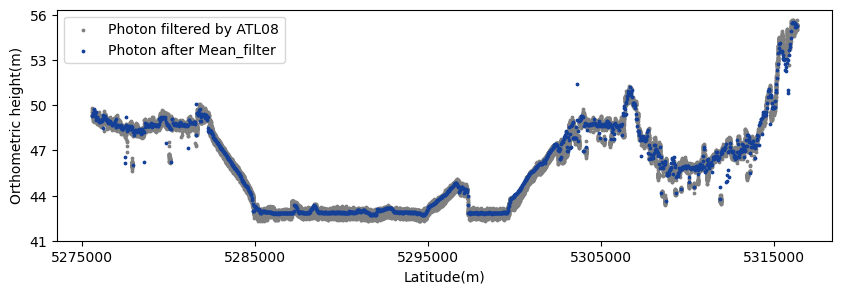

In [29]:
k = 0    
plt.figure(figsize=(10, 3))

plt.scatter(lat*100000, y_origin,  color ="gray",label = 'Photon filtered by ATL08', s=3)
plt.scatter(df_list[k]['mean_lat']*100000, df_list[k]['mean_height'], color ="#144098FF",label = 'Photon after Mean_filter', s=3)
#plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.1)
plt.legend()
plt.yticks(np.arange(41, 57, 3))
plt.xticks(np.arange(5275000, 5320000, 10000))
plt.ticklabel_format(style='plain', axis='x')
plt.ylabel('Orthometric height(m)')
plt.xlabel('Latitude(m)')
plt.show()

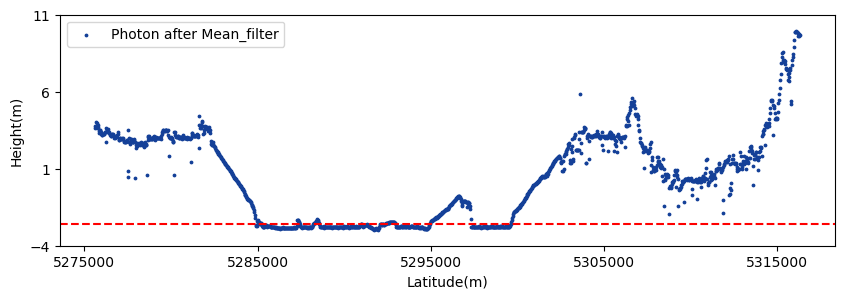

In [301]:
sort_k = np.sort(df_list[k]['OH'])

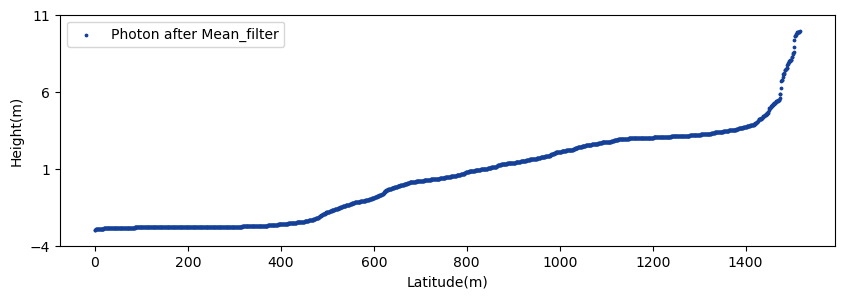

In [309]:
plt.figure(figsize=(10, 3))
plt.scatter(np.arange(0, len(sort_k)), sort_k, color ="#144098FF",label = 'Photon after Mean_filter', s=3)
#plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.1)
plt.legend()
plt.yticks(np.arange(-4, 13, 5))
ax1.set_yticks(np.arange(-5, 13, 5))
# plt.xticks(np.arange(5275000, 5320000, 10000))
# plt.axhline(-2.59, color = 'red', linestyle = '--', zorder=2)
plt.ticklabel_format(style='plain', axis='x')
plt.ylabel('Height(m)')
plt.xlabel('Latitude(m)')
plt.show()

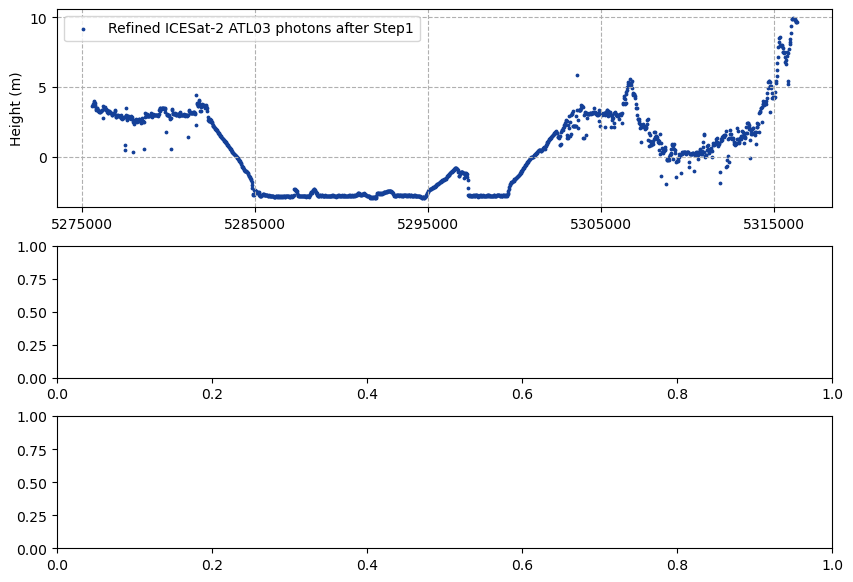

In [295]:
percentile = height_TS['percentile'].dropna()
x = np.arange(len(percentile))

fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, figsize=(10, 7), gridspec_kw={'height_ratios': [3, 2, 2], 'hspace': 0.25})
ax1.ticklabel_format(style='plain', axis='x')  # 关闭科学计数法

# 上方折线图：高度-时间序列
# ax1.scatter(lat*100000, y_origin,  color ="#144098FF",label = 'Photon filtered by ATL08', s=3)
# ax1.plot(df_list[0]['OH'], color ='gray',label = 'height')
ax1.scatter(df_list[0]['mean_lat']*100000, df_list[0]['OH'], color ="#144098FF", s=3, label = 'Refined ICESat-2 ATL03 photons after Step1')
ax1.set_yticks(np.arange(-0, 11, 5))
# ax1.set_ylabel('Height (m)', color='black')
ax1.set_xticks(np.arange(5275000, 5320000, 10000))
# ax1.set_yticks(np.arange(0, 100, 20))
# ax1.set_xlabel('Time Index')
ax1.set_ylabel('Height (m)')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True)
ax1.legend(loc='upper left')
ax1.grid(linestyle='--')


In [18]:
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd

output_path = 'G:\ICESat-2\Region1_map\Thames_map\A2019/No_28_all_points.shp'
geometry = [Point(xy) for xy in zip(re_accumulate['mean_lon'], re_accumulate['mean_lat'])]
gdf = gpd.GeoDataFrame(re_accumulate, geometry=geometry, crs='EPSG:4326')
gdf.to_file(output_path)

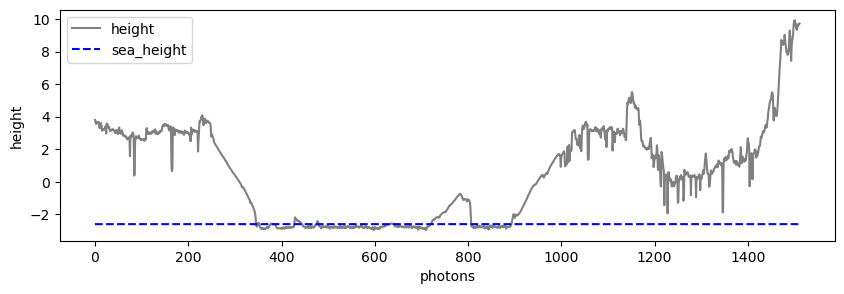

In [188]:
k = 1     
plt.figure(figsize=(10, 3))
plt.plot(df_list[k]['OH'], color ='gray',label = 'height')
plt.plot(df_list[k]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
# plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.1)
plt.legend()
plt.ylabel('height')
plt.xlabel('photons')
plt.show()

In [58]:
re_accumulate[600:]

,distance,mean_height,mean_lon,mean_lat,OSGM,OH
600,5736990.0,44.434227,0.779792,51.518891,44.769001,-0.334774
601,5737020.0,44.440212,0.779751,51.519169,44.769001,-0.328789
602,5737050.0,44.469879,0.779714,51.519420,44.769001,-0.299122
603,5737080.0,44.447636,0.779674,51.519692,44.769001,-0.321365
604,5737110.0,44.485802,0.779633,51.519964,44.769001,-0.283199
...,...,...,...,...,...,...
1373,5766120.0,69.238289,0.739091,51.779478,45.132000,24.106289
1374,5766150.0,69.501816,0.739052,51.779732,45.132000,24.369816
1375,5766180.0,69.712143,0.739008,51.780007,45.132000,24.580143
1376,5766210.0,69.919769,0.738970,51.780241,45.132000,24.787769
